# Progress Report: FFS Rule Environments and Tournament Outcomes

**Question:** After accounting for tournament structure, calendar time, and fishery differences, do tournament-level outcomes differ across observed forward-facing sonar (FFS) rule environments? `Allowed_FFS` records a tournament rule, not anglers’ individual sonar use.

**Where things stand:** The source has 13,968 angler-tournament rows. The primary unadjusted Elite Series contrast uses 81 `Yes (Unrestricted)` and 19 `No FFS Existed` events. Mean tournament median average fish weight is **0.209 lb/fish higher** in the unrestricted group; the 10,000-resample tournament-bootstrap 95% interval is **−0.047 to 0.450** and includes zero. The groups share no years, so this is not an adjusted or causal estimate.

**Difficulties:** Daily participation/duration is unavailable; one weight is negative; repeated fisheries and anglers may induce dependence; 2026 completeness is unknown. Data preparation was a beast to say the least...

**Next:** Verify source metadata and FFS labels, seek official event-duration/participation data, and explore defensible comparisons with temporal overlap. Do not infer bag limits or days fished from catches or place.

**Questions:** Is this explicitly unadjusted bootstrap an adequate progress result? Which FFS categories and event types should be compared if temporal overlap is limited?

## How the extraction and audit fields were created

[`crawler.py`](./crawler.py) is the initial scraper: it finds Bassmaster Fantasy tournament-result pages, parses participant place, angler/player ID, cumulative fish and weight, fantasy points, and the source URL, then writes the raw results CSV. The enriched workflow is in [`new_crawler.py`](./new_crawler.py), with title matching and event metadata in [`bassmaster_master_map.py`](./bassmaster_master_map.py); it writes participant records and a page-level scrape audit under `bassmaster_output/`.

- `supplied_inventory_title_match`: scraped title was normalized and matched to an inventory event for the same year (similarity score at least 0.62, with a top-versus-second candidate margin of at least 0.08). The inventory supplies event name, location, dates, and FFS label.
- `legacy_period_map_fallback_unverified`: no confident title match; metadata falls back to a `(year, periodId)` map, which the code itself marks unverified.
- `unmatched_scraped_title`: neither match nor fallback; scraped title is retained and location/FFS may be unknown.
- `Potential_Duplicate` is set when `(Season_Year, Tournament_ID, Player_ID, Angler_Name)` repeats; flagged rows are not deleted automatically. In this file, none are flagged.
- **Review-flag caveat:** the matcher initially marks confident inventory matches as not needing review, but `clean_results` overwrites that flag using `Metadata_Source != "master_map"`. The matcher emits `supplied_inventory_title_match`, not `master_map`, so the resulting CSV marks every row `True`. Treat that as a pipeline-logic issue, not evidence that every row was individually reviewed or found wrong.

The analysis below preserves the supplied audit fields and reports this behavior rather than silently changing the extraction output.

## Data and reproducibility

Each source row is one angler’s cumulative result in one tournament. Tournament IDs repeat across seasons, so the analysis uses `Season_Year` plus `Tournament_ID` as the event key. `bass_final_cleaned.csv` must be available in the project folder or a nearby `Bass Project` folder. The source URLs point to Bassmaster Fantasy results; metadata and FFS classifications come from the enrichment process above.

In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 7130
N_BOOT = 10_000
np.random.seed(SEED)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

candidates = []
for folder in [Path.cwd(), *Path.cwd().parents]:
    candidates.extend([folder / "bass_final_cleaned.csv", folder / "Bass Project" / "bass_final_cleaned.csv"])
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place bass_final_cleaned.csv in this folder or a nearby Bass Project folder.")

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()
required = ["Season_Year", "Tournament_ID", "Event_Name", "Allowed_FFS", "Player_ID", "Fish_Caught",
            "Weight_Lbs_Calculated", "Avg_Fish_Weight", "Waterbody", "Metadata_Source",
            "Metadata_Needs_Review", "Potential_Duplicate"]
missing = sorted(set(required) - set(df.columns))
if missing:
    raise ValueError(f"Missing required columns: {missing}")
df["Tournament_Key"] = df["Season_Year"].astype(int).astype(str) + "_" + df["Tournament_ID"].astype(int).astype(str)
print(f"Loaded {len(df):,} angler-event rows from {DATA_PATH.name}; {df['Tournament_Key'].nunique()} season-specific tournaments.")
print("Python", platform.python_version(), "pandas", pd.__version__, "NumPy", np.__version__)

Loaded 13,968 angler-event rows from bass_final_cleaned.csv; 150 season-specific tournaments.
Python 3.13.1 pandas 2.3.3 NumPy 2.1.0


In [2]:
# Validate event keys and source-record quality before deriving analysis measures.
consistency = df.groupby("Tournament_Key").agg(
    Event_Names=("Event_Name", "nunique"), Waterbodies=("Waterbody", "nunique"),
    FFS_Labels=("Allowed_FFS", "nunique"), Dates=("Tournament_Dates", "nunique"),
)
inconsistent_keys = consistency.index[(consistency > 1).any(axis=1)]
duplicate_rows = df.duplicated(keep=False)
duplicate_angler_events = df.duplicated(["Tournament_Key", "Player_ID", "Angler_Name"], keep=False)
negative_weight = df["Weight_Lbs_Calculated"].lt(0)

quality = pd.Series({
    "Inconsistent tournament keys": len(inconsistent_keys),
    "Exact duplicate rows": int(duplicate_rows.sum()),
    "Potential_Duplicate=True": int(df["Potential_Duplicate"].fillna(False).astype(bool).sum()),
    "Repeated angler-event keys (independent check)": int(duplicate_angler_events.sum()),
    "Negative fish counts": int(df["Fish_Caught"].lt(0).sum()),
    "Negative calculated weights": int(negative_weight.sum()),
    "Metadata_Needs_Review=True": int(df["Metadata_Needs_Review"].fillna(False).astype(bool).sum()),
}, name="Count")
display(quality.to_frame())
print("Metadata-source counts:")
display(df["Metadata_Source"].value_counts(dropna=False).rename("Rows").to_frame())
print("FFS label by metadata source:")
display(pd.crosstab(df["Allowed_FFS"], df["Metadata_Source"], dropna=False))
if len(inconsistent_keys):
    display(df.loc[df["Tournament_Key"].isin(inconsistent_keys)].sort_values("Tournament_Key"))
if duplicate_angler_events.any():
    display(df.loc[duplicate_angler_events, ["Tournament_Key", "Player_ID", "Angler_Name", "Place"]])

# Preserve the raw negative value; exclude it only from weight-derived measures.
df["Weight_Lbs_Analytic"] = df["Weight_Lbs_Calculated"].where(df["Weight_Lbs_Calculated"].ge(0))
df["Avg_Fish_Weight_Calc"] = np.where(
    df["Fish_Caught"].gt(0) & df["Weight_Lbs_Analytic"].notna(),
    df["Weight_Lbs_Analytic"] / df["Fish_Caught"], np.nan,
)
print("Suspicious weight record(s):")
display(df.loc[negative_weight, ["Season_Year", "Event_Name", "Angler_Name", "Fish_Caught", "Weight_Lbs_Calculated", "Source_URL"]])

,Count
Inconsistent tournament keys,0
Exact duplicate rows,0
Potential_Duplicate=True,0
Repeated angler-event keys (independent check),0
Negative fish counts,0
Negative calculated weights,1
Metadata_Needs_Review=True,13968


Metadata-source counts:


,Rows
Metadata_Source,
supplied_inventory_title_match,11681
unmatched_scraped_title,1610
legacy_period_map_fallback_unverified,677


FFS label by metadata source:


Metadata_Source,legacy_period_map_fallback_unverified,supplied_inventory_title_match,unmatched_scraped_title
Allowed_FFS,,,
No,0,399,0
No FFS Existed,0,2080,0
Yes (Restricted),216,1314,0
Yes (Unrestricted),461,7888,0
allowed,0,0,339
unavailable,0,0,1271


Suspicious weight record(s):


,Season_Year,Event_Name,Angler_Name,Fish_Caught,Weight_Lbs_Calculated,Source_URL
2713,2015,Elite Series,Scott Ashmore,0,-1.000,https://bassmasterfantasy.com/TournamentDetail...


## Angler-level exploration

These plots show source-row distributions for context only. Angler rows within a tournament are not independent FFS comparison units.

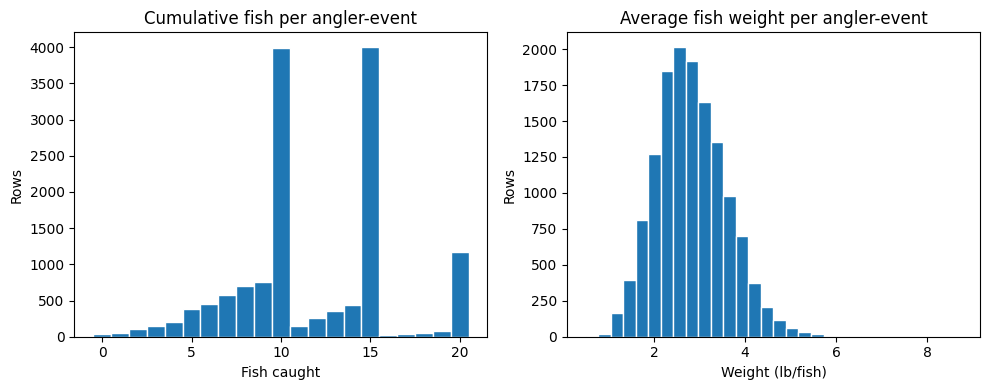

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(df.loc[df["Fish_Caught"].ge(0), "Fish_Caught"], bins=np.arange(-0.5, 21.5, 1), edgecolor="white")
axes[0].set(title="Cumulative fish per angler-event", xlabel="Fish caught", ylabel="Rows")
axes[1].hist(df["Avg_Fish_Weight_Calc"].dropna(), bins=30, edgecolor="white")
axes[1].set(title="Average fish weight per angler-event", xlabel="Weight (lb/fish)", ylabel="Rows")
plt.tight_layout()
plt.show()

## Tournament-level dataset

Summarize angler results into one row per tournament. Fish-count measures include valid nonnegative counts; weight measures omit the one negative calculated weight. Average fish weight is conditional on catching fish and remains affected by selection, culling, event format, and days fished.

In [4]:
valid_counts = df.loc[df["Fish_Caught"].ge(0)].copy()
tournament_df = valid_counts.groupby("Tournament_Key", as_index=False).agg(
    Season_Year=("Season_Year", "first"), Event_Name=("Event_Name", "first"),
    Waterbody=("Waterbody", "first"), Allowed_FFS=("Allowed_FFS", "first"),
    Field_Size=("Player_ID", "nunique"),
    Median_Fish_Caught=("Fish_Caught", "median"),
    Zero_Catch_Rate=("Fish_Caught", lambda x: x.eq(0).mean()),
    Median_Total_Weight=("Weight_Lbs_Analytic", "median"),
    Median_Avg_Fish_Weight=("Avg_Fish_Weight_Calc", "median"),
    Mean_Avg_Fish_Weight=("Avg_Fish_Weight_Calc", "mean"),
    Q75_Avg_Fish_Weight=("Avg_Fish_Weight_Calc", lambda x: x.quantile(.75)),
    Metadata_Review_Rate=("Metadata_Needs_Review", "mean"),
)
if not tournament_df["Tournament_Key"].is_unique:
    raise AssertionError("Expected exactly one row per tournament.")
print(f"Analysis-ready tournament rows: {len(tournament_df)}")
display(tournament_df[["Tournament_Key", "Season_Year", "Event_Name", "Waterbody", "Allowed_FFS",
                       "Field_Size", "Median_Avg_Fish_Weight"]].head())

event_frame = tournament_df.drop_duplicates("Tournament_Key")
print("Tournament counts by recorded FFS label:")
display(event_frame["Allowed_FFS"].value_counts().rename("Tournaments").to_frame())
ffs_by_year = pd.crosstab(event_frame["Season_Year"], event_frame["Allowed_FFS"])
display(ffs_by_year)

Analysis-ready tournament rows: 150


,Tournament_Key,Season_Year,Event_Name,Waterbody,Allowed_FFS,Field_Size,Median_Avg_Fish_Weight
0,2012_1,2012,Bassmaster Classic,Red River,No FFS Existed,49,2.458
1,2012_2,2012,Elite Series,St. Johns River,No FFS Existed,99,2.263
2,2012_3,2012,Elite Series,Lake Okeechobee,No FFS Existed,99,2.483
3,2012_4,2012,Elite Series,Bull Shoals Lake,No FFS Existed,99,2.688
4,2012_5,2012,Elite Series,Douglas Lake,No FFS Existed,99,2.367


Tournament counts by recorded FFS label:


,Tournaments
Allowed_FFS,
Yes (Unrestricted),89
No FFS Existed,22
Yes (Restricted),16
unavailable,14
allowed,5
No,4


Allowed_FFS,No,No FFS Existed,Yes (Restricted),Yes (Unrestricted),allowed,unavailable
Season_Year,,,,,,
2012,0,9,0,0,0,0
2013,0,7,0,0,0,2
2014,0,6,0,0,0,3
2015,0,0,0,8,0,2
2016,0,0,0,10,0,1
2017,0,0,0,7,0,4
2018,0,0,0,8,0,2
2019,0,0,0,8,3,0
2020,0,0,0,9,1,0


## Course method: event-level bootstrap

The primary contrast is the difference in the **mean tournament median average fish weight** for Elite Series events labeled `Yes (Unrestricted)` versus `No FFS Existed`. Each draw resamples tournaments within each label. This estimates uncertainty under event-level resampling; it does not adjust for the non-overlapping years, waterbody scheduling, or recurring anglers.

Elite Series tournaments:


,Tournaments
Allowed_FFS,
Yes (Unrestricted),81
No FFS Existed,19


,Outcome,Contrast,n A,n B,Difference (lb/fish),95% bootstrap interval lower,upper,Resamples
0,Median_Avg_Fish_Weight,Yes (Unrestricted) minus No FFS Existed,81,19,0.209,-0.047,0.450,10000


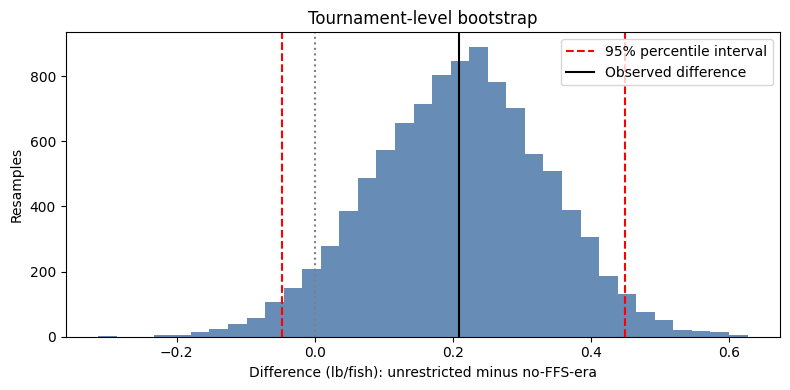

Interval includes zero: True


In [5]:
GROUP_A, GROUP_B = "Yes (Unrestricted)", "No FFS Existed"
PRIMARY_OUTCOME = "Median_Avg_Fish_Weight"
primary = tournament_df.loc[
    tournament_df["Event_Name"].eq("Elite Series")
    & tournament_df["Allowed_FFS"].isin([GROUP_A, GROUP_B])
].copy()

def bootstrap_difference(data, outcome, group_a=GROUP_A, group_b=GROUP_B, n_boot=N_BOOT, seed=SEED):
    a = data.loc[data["Allowed_FFS"].eq(group_a), outcome].dropna().to_numpy()
    b = data.loc[data["Allowed_FFS"].eq(group_b), outcome].dropna().to_numpy()
    if min(len(a), len(b)) < 2:
        raise ValueError("Each group needs at least two tournaments.")
    local_rng = np.random.default_rng(seed)
    draws = np.empty(n_boot)
    for i in range(n_boot):
        draws[i] = local_rng.choice(a, len(a), replace=True).mean() - local_rng.choice(b, len(b), replace=True).mean()
    return {"n_a": len(a), "n_b": len(b), "difference": a.mean() - b.mean(),
            "ci_low": np.quantile(draws, .025), "ci_high": np.quantile(draws, .975), "draws": draws}

result = bootstrap_difference(primary, PRIMARY_OUTCOME)
print("Elite Series tournaments:")
display(primary["Allowed_FFS"].value_counts().rename("Tournaments").to_frame())
display(pd.DataFrame([{
    "Outcome": PRIMARY_OUTCOME, "Contrast": f"{GROUP_A} minus {GROUP_B}",
    "n A": result["n_a"], "n B": result["n_b"], "Difference (lb/fish)": result["difference"],
    "95% bootstrap interval lower": result["ci_low"], "upper": result["ci_high"], "Resamples": N_BOOT,
}]))
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(result["draws"], bins=35, color="#4C78A8", alpha=.85)
ax.axvline(0, color="gray", linestyle=":")
ax.axvline(result["ci_low"], color="red", linestyle="--")
ax.axvline(result["ci_high"], color="red", linestyle="--", label="95% percentile interval")
ax.axvline(result["difference"], color="black", label="Observed difference")
ax.set(xlabel="Difference (lb/fish): unrestricted minus no-FFS-era", ylabel="Resamples",
       title="Tournament-level bootstrap")
ax.legend()
plt.tight_layout()
plt.show()
print("Interval includes zero:", result["ci_low"] <= 0 <= result["ci_high"])

## Time and fishery context

Describe coverage rather than claiming adjustment. Do not permute FFS labels globally: the two primary categories have no shared calendar years. Repeated fisheries are shown to make that limitation visible.

,Season_Year,Tournaments,Mean_Tournament_Median_Avg_Fish_Weight
0,2012,9,2.495
1,2013,9,2.627
2,2014,9,2.929
3,2015,10,2.797
4,2016,11,2.668
5,2017,11,3.014
6,2018,10,2.487
7,2019,11,2.836
8,2020,10,2.879
9,2021,10,2.696


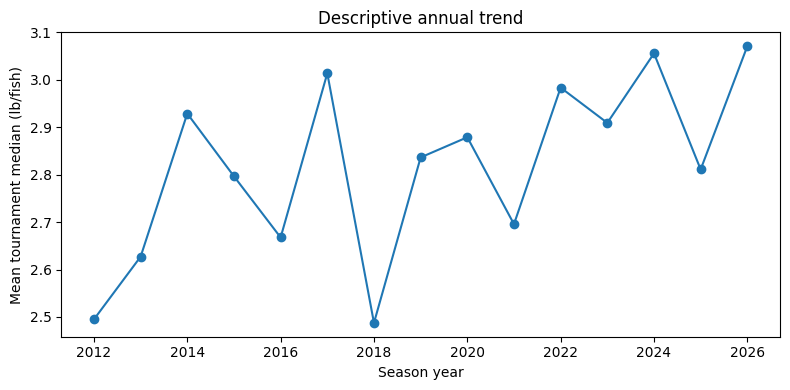

Shared primary-label years: []
Waterbodies in both labels: 9


Allowed_FFS,Yes (Unrestricted),No FFS Existed
Waterbody,,
Cayuga Lake,1,1
Lake Dardanelle,1,1
Lake Okeechobee,1,1
Lake Seminole,1,1
Mississippi River,4,2
Sabine River,4,1
St. Johns River,5,1
St. Lawrence River,8,1
Toledo Bend Reservoir,2,2


2026 contains records, but the supplied extract does not establish season completeness.


In [6]:
annual = tournament_df.groupby("Season_Year", as_index=False).agg(
    Tournaments=("Tournament_Key", "nunique"),
    Mean_Tournament_Median_Avg_Fish_Weight=("Median_Avg_Fish_Weight", "mean"),
)
display(annual)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(annual["Season_Year"], annual["Mean_Tournament_Median_Avg_Fish_Weight"], marker="o")
ax.set(xlabel="Season year", ylabel="Mean tournament median (lb/fish)", title="Descriptive annual trend")
plt.tight_layout()
plt.show()
years_a = set(primary.loc[primary["Allowed_FFS"].eq(GROUP_A), "Season_Year"])
years_b = set(primary.loc[primary["Allowed_FFS"].eq(GROUP_B), "Season_Year"])
waterbody_labels = pd.crosstab(primary["Waterbody"], primary["Allowed_FFS"]).reindex(columns=[GROUP_A, GROUP_B], fill_value=0)
shared_waterbodies = waterbody_labels.index[waterbody_labels.gt(0).all(axis=1)]
print("Shared primary-label years:", sorted(years_a & years_b))
print("Waterbodies in both labels:", len(shared_waterbodies))
display(waterbody_labels.loc[shared_waterbodies])
print("2026 contains records, but the supplied extract does not establish season completeness.")

## Sensitivity checks

Alternative outcome summaries and a waterbody-block bootstrap check how the conclusion depends on the event summary and repeated fisheries. Block resampling keeps all events from a sampled waterbody together, but still does not address calendar-time confounding or anglers who recur across fisheries.

In [7]:
sensitivity = []
for offset, outcome in enumerate(["Mean_Avg_Fish_Weight", "Q75_Avg_Fish_Weight", "Median_Total_Weight"], start=1):
    check = bootstrap_difference(primary, outcome, seed=SEED + offset)
    sensitivity.append({"Outcome": outcome, "Difference": check["difference"],
                        "95% lower": check["ci_low"], "95% upper": check["ci_high"]})

def waterbody_block_bootstrap(data, outcome, n_boot=N_BOOT, seed=SEED + 20):
    group_blocks = {}
    for label in [GROUP_A, GROUP_B]:
        subset = data.loc[data["Allowed_FFS"].eq(label), ["Waterbody", outcome]].dropna()
        group_blocks[label] = {key: block[outcome].to_numpy()
                               for key, block in subset.groupby("Waterbody")}
    blocks_a, blocks_b = group_blocks[GROUP_A], group_blocks[GROUP_B]
    if min(len(blocks_a), len(blocks_b)) < 2:
        raise ValueError("Each label needs at least two waterbody blocks.")
    rng = np.random.default_rng(seed)
    draws = np.empty(n_boot)
    keys_a, keys_b = list(blocks_a), list(blocks_b)
    for i in range(n_boot):
        a_keys = rng.choice(keys_a, len(keys_a), replace=True)
        b_keys = rng.choice(keys_b, len(keys_b), replace=True)
        a = np.concatenate([blocks_a[key] for key in a_keys])
        b = np.concatenate([blocks_b[key] for key in b_keys])
        draws[i] = a.mean() - b.mean()
    return {"difference": np.concatenate(list(blocks_a.values())).mean() - np.concatenate(list(blocks_b.values())).mean(),
            "ci_low": np.quantile(draws, .025), "ci_high": np.quantile(draws, .975),
            "blocks_a": len(blocks_a), "blocks_b": len(blocks_b)}

block_check = waterbody_block_bootstrap(primary, PRIMARY_OUTCOME)
sensitivity.append({"Outcome": "Primary, waterbody-block bootstrap",
                    "Difference": block_check["difference"], "95% lower": block_check["ci_low"],
                    "95% upper": block_check["ci_high"],
                    "Waterbody blocks A": block_check["blocks_a"], "Waterbody blocks B": block_check["blocks_b"]})
display(pd.DataFrame(sensitivity))
print("Metadata-clean sensitivity available?", bool(primary["Metadata_Review_Rate"].eq(0).any()))

,Outcome,Difference,95% lower,95% upper,Waterbody blocks A,Waterbody blocks B
0,Mean_Avg_Fish_Weight,0.208,-0.038,0.444,NaN,NaN
1,Q75_Avg_Fish_Weight,0.246,-0.048,0.508,NaN,NaN
2,Median_Total_Weight,-0.035,-3.990,3.907,NaN,NaN
3,"Primary, waterbody-block bootstrap",0.209,-0.137,0.525,37.000,17.000


Metadata-clean sensitivity available? False


## Findings, limitations, and next steps

The primary interval includes zero; this does not prove equivalence. The event bootstrap quantifies variability among sampled tournaments but does not account for different historical periods, event formats, environmental conditions, or every dependence from recurring anglers and fisheries. `Median_Avg_Fish_Weight` is conditional on positive catch and is not independent of duration, selection, or culling. No bag-limit, days-fished, or percent-of-limit measures are created.

One row has a negative calculated weight (zero fish, −1 lb); it is excluded only from weight metrics and should be checked against its source. All rows are marked for metadata review because of the `new_crawler.py` flag logic described above; this status is not a record-by-record verification outcome. FFS labels based on fallback/unmatched metadata and the completeness of 2026 need human confirmation.

**Next steps:** verify FFS labels and metadata logic; confirm 2026 coverage; obtain authoritative daily participation/duration data; consider comparisons with genuine temporal overlap; and ask whether a waterbody-block bootstrap is suitable as the final dependence-aware analysis.

In [8]:
# Final audit: no inferred bag-limit/days-fished variables enter the analysis.
assert tournament_df["Tournament_Key"].is_unique
assert tournament_df["Allowed_FFS"].notna().all() and tournament_df["Waterbody"].notna().all()
assert tournament_df["Zero_Catch_Rate"].between(0, 1).all()
assert len(result["draws"]) == N_BOOT
for forbidden in ["Bag_Limit", "Days_Competed_Est", "Eligible_Bag_Limit", "Pct_Eligible_Limit", "Pct_Limit"]:
    assert forbidden not in df.columns
print("Audit passed | angler rows:", len(df_raw), "| tournaments:", len(tournament_df),
      "| fisheries:", tournament_df["Waterbody"].nunique(), "| bootstrap draws:", len(result["draws"]))

Audit passed | angler rows: 13968 | tournaments: 150 | fisheries: 62 | bootstrap draws: 10000
